# Import Libraries

In [2]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [3]:
(x_train,y_train) , (x_test,y_test) = keras.datasets.mnist.load_data()

**INSIGHTS** : Loads handwritten digit images and their labels. MNIST provides a standard dataset for training and testing. Which splitted x_train,y_train , x_test and y_test while creating loading the data.Provides large, labeled data for learning. Ensures consistency and reliability in results.

# Basic Checks

In [4]:
x_train.shape

(60000, 28, 28)

In [5]:
y_train.shape

(60000,)

In [6]:
x_test.shape

(10000, 28, 28)

In [7]:
x_train[0].shape

(28, 28)

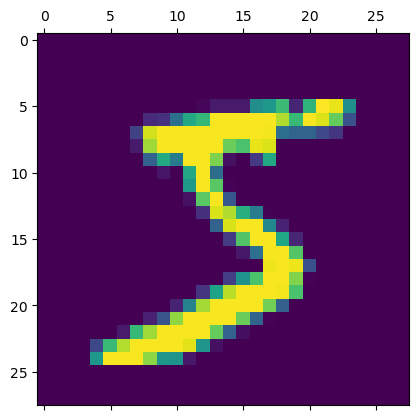

In [8]:
plt.matshow(x_train[0])
plt.show()

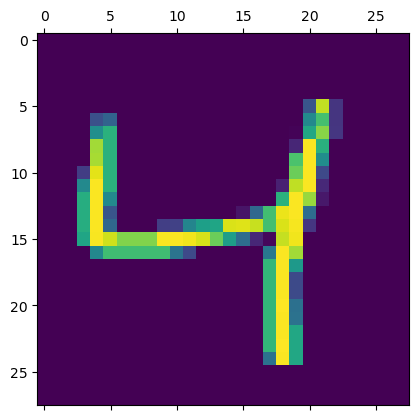

In [9]:
plt.matshow(x_train[2])
plt.show()

In [10]:
y_train[2]

np.uint8(4)

In [11]:
y_train[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

### Data Preprocessing

In [12]:
x_train = x_train / 255
x_test = x_test / 255

**INSIGHTS** : Normalizes pixel values (0–255 → 0–1) for better learning. Reshapes data if needed to match model input. After doing this the accuracy score will improve and predicts much better. Reshapes data to match model input format.
Reduces computational complexity.

### Reshape (1D)

In [13]:
x_train_flatten = x_train.reshape(len(x_train),28*28)
x_test_flatten = x_test.reshape(len(x_test),28*28)

In [14]:
x_train_flatten.shape

(60000, 784)

In [15]:
x_test_flatten.shape

(10000, 784)

**INSIGHTS** : Converts 28×28 image into a 784-length vector. Needed because Dense layers only accept 1D input. Converts 2D image into 1D vector. Informs about each and every every pixels and Simplifies data structure.
Loses spatial relationships between pixels.

# Model Building

In [16]:
from tensorflow import keras
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),
    keras.layers.Dense(100, activation='relu'),
    keras.layers.Dense(50, activation='relu'), 
    keras.layers.Dense(10, activation='sigmoid') 
]) 


C:\Users\Praveen\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
model.compile( optimizer='adam',
loss='sparse_categorical_crossentropy',
metrics=['accuracy']
) 

model.fit(x_train, y_train,epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9252 - loss: 0.2597
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9663 - loss: 0.1117
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9747 - loss: 0.0797
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9808 - loss: 0.0605
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9844 - loss: 0.0488


**INSIGHTS** : Creating 2 Hidden Layers for best Output with activation funtion "relu". Defines optimizer, loss, and metrics. Adam optimizer adjusts learning efficiently. Loss function measures prediction error. Prepares model for training.Model learns from data over multiple epochs. Uses forward pass and backpropagation. Weights are updated to reduce loss. Improves accuracy gradually.

# Evaluation

In [18]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9743 - loss: 0.0818   


[0.08177526295185089, 0.9743000268936157]

**INSIGHTS** : This model gives Accuracy around 98 which model is good for real world Projects. Tests model on unseen test data. Measures performance using accuracy. Detects overfitting or underfitting. Validates model effectiveness.

# Prediction

In [19]:
y_pred2 = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [20]:
y_pred_label2 = [np.argmax(i) for i in y_pred2]

In [21]:
cm2 = tf.math.confusion_matrix(labels=y_test,predictions=y_pred_label2)
cm2

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 942,    0,    1,    0,    4,    1,    8,    3,    7,   14],
       [   0, 1127,    2,    1,    0,    1,    2,    1,    1,    0],
       [   4,    5,  993,    7,    3,    0,    6,    4,    7,    3],
       [   0,    0,    2,  992,    0,    4,    0,    6,    5,    1],
       [   0,    2,    2,    1,  955,    0,    5,    2,    1,   14],
       [   1,    0,    0,   15,    1,  863,    5,    2,    3,    2],
       [   2,    4,    0,    0,    3,    5,  942,    0,    2,    0],
       [   0,    1,    8,    3,    1,    0,    0, 1007,    0,    8],
       [   1,    2,    2,    7,    2,    4,    2,    5,  941,    8],
       [   1,    3,    0,   10,    7,    0,    1,    6,    0,  981]],
      dtype=int32)>

# Prediction (Visualization)

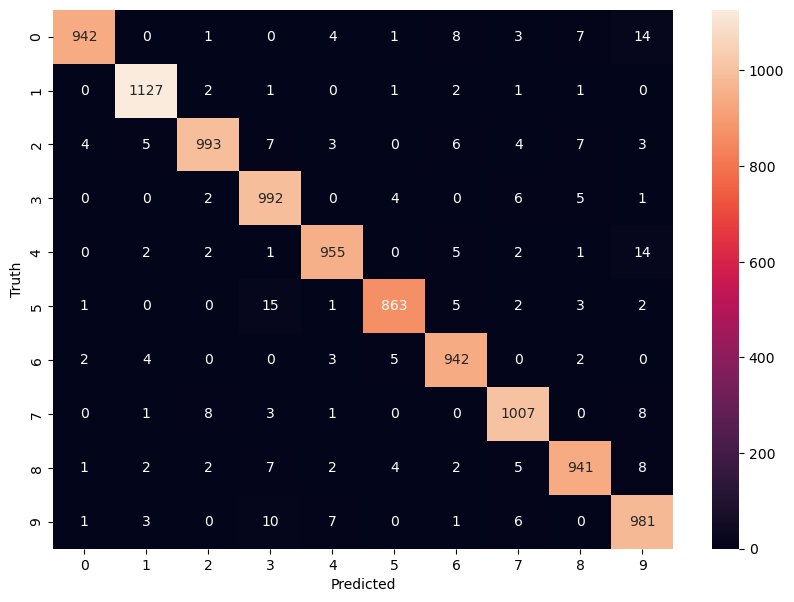

In [22]:
import seaborn as sns
plt.figure(figsize = (10,7))
sns.heatmap(cm2,annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

**INSIGHTS** : Visual representation of model performance using predicted vs actual labels.
Diagonal values show correct predictions; off-diagonal show errors.
Helps identify which digits are getting confused (e.g., 3 vs 5).
Useful for improving model by analyzing misclassification patterns.

# Visualization (Predicted vs Actual)

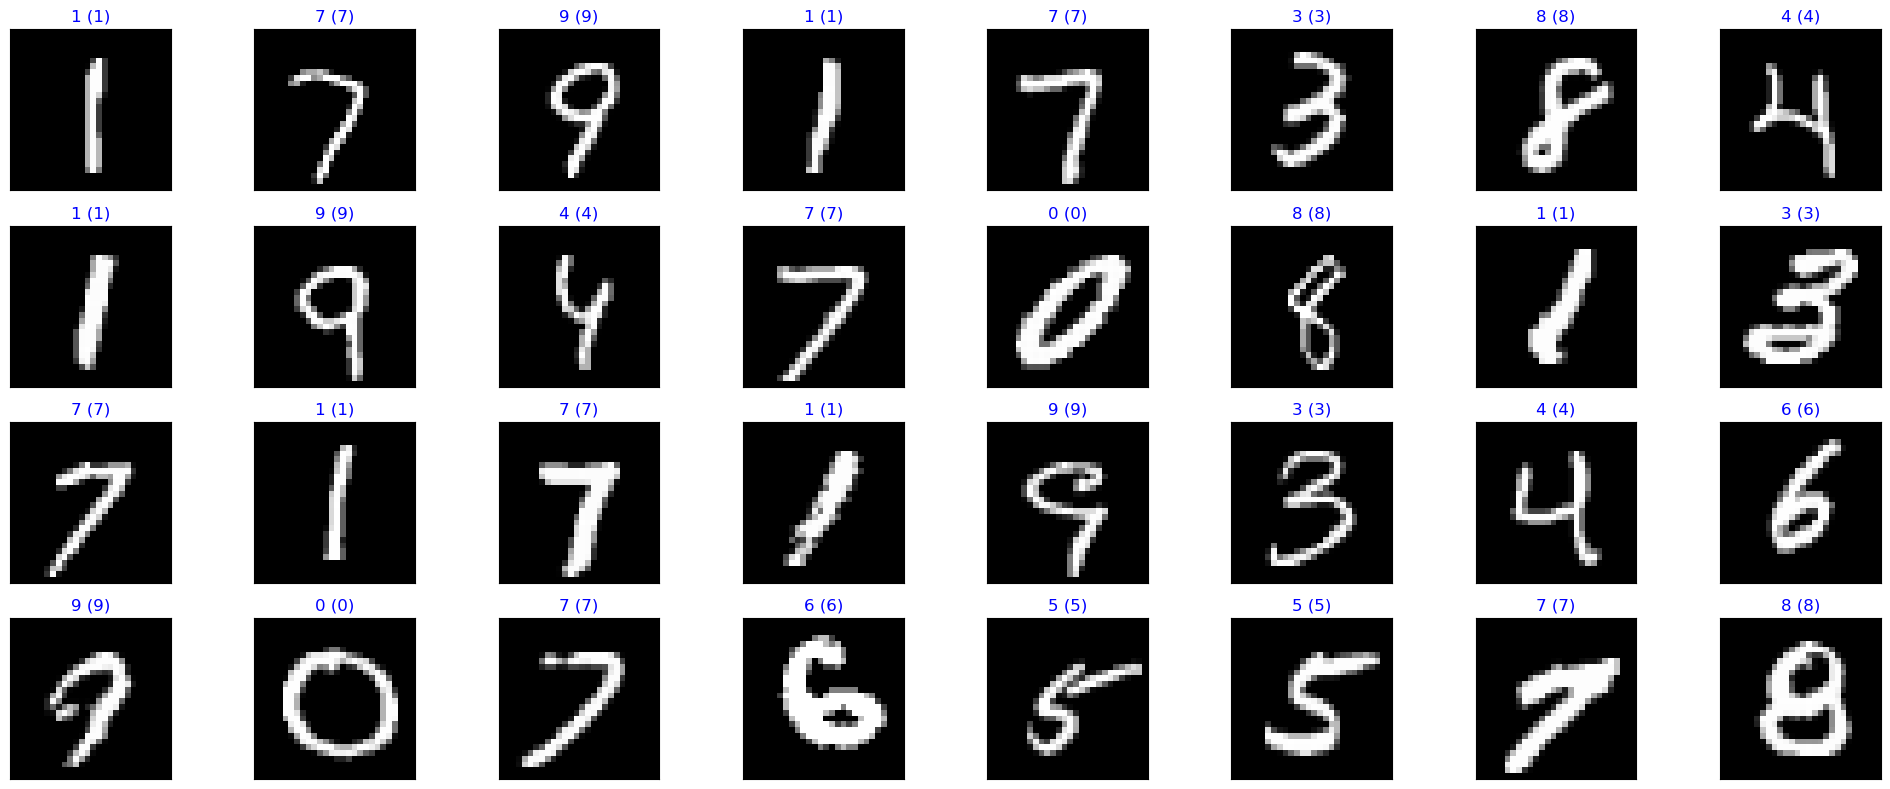

In [23]:
fig = plt.figure(figsize=(20, 8))

for i, idx in enumerate(np.random.choice(x_test.shape[0], size=32, replace=False)):
    ax = fig.add_subplot(4, 8, i + 1, xticks=[], yticks=[])
    
    ax.imshow(x_test[idx], cmap='gray')  
    
    pred_idx = np.argmax(y_pred2[idx])
    true_idx = y_test[idx]  
    
    ax.set_title("{} ({})".format(pred_idx, true_idx),
                 color=("blue" if pred_idx == true_idx else "red"))

plt.tight_layout()
plt.show()

**INSIGHTS** : Displays images with predictions.
Compares predicted vs actual labels.
Highlights correct and incorrect cases.
Helps in model analysis and debugging. This shows how Accurate the model is predicting Almost every thing is perfect. With this Visuals can easily see the Prediction.

# Problems Faced 

**During Model Development :** Simple Dense model loses spatial information, making image recognition harder.


**Reasons for Misclassification Errors :** Similar digit shapes create ambiguity, leading to misclassification.


**Issues Encountered in Training and Testing :** Improper choice of activation functions or output layer affects learning.


**Factors Affecting Model Performance :** Limited tuning (epochs, neurons, layers) prevents optimal performance.

# Analysis of the Project

This project demonstrates the implementation of a neural network for handwritten digit recognition using the MNIST dataset. The model successfully learns patterns from pixel data and classifies digits with good accuracy, showing the effectiveness of deep learning in image classification tasks.

Although a basic Dense neural network was used, the model was able to identify important features such as edges and shapes. However, due to the use of a Flatten layer, spatial relationships between pixels were not fully utilized, which slightly limits performance compared to more advanced architectures like CNNs.

The project also highlights key challenges such as misclassification of similar digits, sensitivity to hyperparameters, and the importance of choosing appropriate activation functions and output layers. These factors directly influence the model’s accuracy and generalization ability.

Overall, this project provides a strong foundation in neural networks, data preprocessing, model training, and evaluation. It can be further enhanced by using Convolutional Neural Networks, hyperparameter tuning, and regularization techniques to achieve higher accuracy and robustness.

**This project serves as a practical introduction to deep learning concepts and demonstrates how machine learning models can be applied to real-world pattern recognition problems.**